# Rebaño y estructura de edad en un modelo presa-depredador

Partimos del modelo **Wolf Sheep Predation** de la biblioteca de NetLogo (Wilensky, 1997) y le hacemos dos cambios a las ovejas:

1. **Comportamiento de rebaño:** en lugar de moverse al azar, se mueven con las reglas del modelo **Flocking** (boids): separación, alineación y cohesión.
2. **Reproducción gradual:** una oveja solo puede reproducirse cuando alcanza cierta edad y cierta energía, como en el modelo de cucarachas con huevos y adultas.

**Cómo está organizado este trabajo.**

* **Python (este notebook).** Reimplementamos ambos modelos de NetLogo en Python, siguiendo su código, para poder correr cientos de simulaciones y hacer estadística en el mismo lugar donde se explica todo.
* **NetLogo (archivo aparte).** El modelo modificado está en [`Wolf-Sheep-Rebano.nlogo`](https://github.com/uncrayon/biologia-matematica/blob/main/assets/netlogo/Wolf-Sheep-Rebano.nlogo): agrega los interruptores `rebano?` y `reproduccion-gradual?`, los deslizadores de las reglas de parvada, `edad-madurez` y `energia-minima`, y experimentos de BehaviorSpace. Lo ejecutamos en NetLogo 6.4.0 y sus resultados coinciden con los de la versión en Python (sección 7).

**Contenido**

1. El modelo presa-depredador y el movimiento de las ovejas.
2. El modelo de parvada (boids): reglas, parámetros, transición orden-desorden y obstáculos.
3. Ovejas en rebaño.
4. Reproducción gradual.
5. Estadística de muchas simulaciones: estabilidad, oscilaciones, extinción y una transición.
6. Comparación con el modelo continuo.
7. Verificación con NetLogo.

## 1. El modelo presa-depredador

En la versión `sheep-wolves-grass` del modelo de NetLogo, en un mundo periódico de 51 × 51 parcelas:

* **Ovejas:** cada tick se mueven, gastan 1 de energía, comen pasto si su parcela es verde (+4 de energía, la parcela se vuelve café), mueren si su energía es negativa y se reproducen con probabilidad 4 % (la cría se lleva la mitad de la energía).
* **Lobos:** se mueven, gastan 1 de energía, se comen una oveja de su parcela si hay alguna (+20), mueren sin energía y se reproducen con probabilidad 5 %.
* **Pasto:** una parcela café vuelve a ser verde 30 ticks después de ser comida.

**El movimiento por defecto de las ovejas** es `rt random 50  lt random 50  fd 1`: giran a la derecha un ángulo entero entre 0 y 49 grados, luego a la izquierda otro, y avanzan un paso. Igual que las hormigas del problema 6, es una **caminata aleatoria correlacionada** (giros con distribución triangular entre −49° y 49°). Además:

* **¿Es aleatorio de verdad?** En dos sentidos, no del todo. Primero, los números "aleatorios" de la computadora son pseudoaleatorios: una secuencia determinista que solo parece azar (por eso fijar una semilla reproduce una simulación). Segundo, y más importante biológicamente: el movimiento es **ciego**. Las ovejas no buscan pasto, no huyen de los lobos y no se juntan entre ellas. Su posición es independiente de todo lo demás.
* **¿Cómo influye en la dinámica?** Como las ovejas se dispersan uniformemente, los encuentros oveja-lobo ocurren a una tasa proporcional al producto de las densidades: es la hipótesis de **acción de masas** de Lotka–Volterra. El modelo de agentes se comporta como una versión con ruido y espacio de esas ecuaciones.
* **¿Así se mueven las ovejas en la realidad?** No. Las ovejas son animales muy gregarios: pastan y se desplazan en grupo, siguen a sus vecinas y, ante una amenaza, corren hacia el centro del grupo (King et al., 2012, midieron con GPS cómo un rebaño se compacta cuando se acerca un perro pastor: es la idea de la "manada egoísta" de Hamilton). Por eso tiene sentido darles reglas de rebaño.

La reimplementación está en las dos celdas siguientes. La primera contiene las reglas de parvada (que usan tanto el modelo Flocking como las ovejas con rebaño) y la segunda el modelo presa-depredador.

*Nota técnica:* en NetLogo los agentes actúan uno tras otro dentro de cada tick. Aquí todas las ovejas se mueven a la vez y después comen en orden aleatorio (si dos ovejas llegan a la misma parcela verde, solo una come); lo mismo los lobos al cazar. No cambia la dinámica colectiva.

In [1]:
# ============================================================
# Reglas de parvada (modelo "Flocking" de NetLogo, Wilensky 1998)
# ============================================================
import numpy as np
from scipy.spatial import cKDTree      # búsqueda rápida de vecinos (con bordes periódicos)


def ajustar_angulo(a):
    """Lleva un ángulo (en grados) al intervalo [-180, 180): como subtract-headings de NetLogo."""
    return (a + 180) % 360 - 180


def girar_a_lo_mas(rumbo, giro, maximo):
    """turn-at-most: gira `giro` grados, pero nunca más de `maximo` en valor absoluto."""
    return rumbo + np.clip(giro, -maximo, maximo)


def giros_de_parvada(x, y, rumbo, lado, vision, min_sep, max_alinear, max_cohesion, max_separar):
    """
    Un paso de las reglas del modelo Flocking de NetLogo para todos los individuos a la vez.

    Para cada individuo:
      * compañeros = los demás dentro de un radio `vision` (en un mundo periódico de `lado` x `lado`);
      * si el vecino más cercano está a menos de `min_sep`: SEPARACIÓN (girar para alejarse
        de la dirección de ese vecino, a lo más `max_separar` grados);
      * si no: ALINEACIÓN (girar hacia el rumbo promedio de los compañeros, a lo más
        `max_alinear`) y COHESIÓN (girar hacia la posición promedio de los compañeros,
        a lo más `max_cohesion`).
    Regresa el arreglo de rumbos nuevos (grados; 0 = norte, sentido horario).
    """
    n = len(x)
    if n < 2:
        return rumbo.copy()
    pos = np.column_stack([x % lado, y % lado])       # coordenadas en [0, lado)
    arbol = cKDTree(pos, boxsize=lado)                  # boxsize -> distancias periódicas
    pares = arbol.query_pairs(vision, output_type="ndarray")
    h = np.deg2rad(rumbo)

    # Vecino más cercano (k=2 porque el primero es uno mismo).
    dist, idx = arbol.query(pos, k=2)
    d_cercano, j_cercano = dist[:, 1], idx[:, 1]

    # Sumas para alineación (componentes del rumbo de los compañeros) y cohesión
    # (componentes del vector unitario que apunta hacia cada compañero).
    ax_ = np.zeros(n); ay_ = np.zeros(n)
    cx_ = np.zeros(n); cy_ = np.zeros(n)
    tiene = np.zeros(n, bool)
    if len(pares):
        i, j = pares[:, 0], pares[:, 1]
        d = pos[j] - pos[i]
        d -= lado * np.round(d / lado)                  # imagen mínima (mundo periódico)
        r = np.hypot(d[:, 0], d[:, 1])
        ok = r > 0
        i, j, d, r = i[ok], j[ok], d[ok], r[ok]
        ux, uy = d[:, 0] / r, d[:, 1] / r               # de i hacia j
        np.add.at(ax_, i, np.sin(h[j])); np.add.at(ay_, i, np.cos(h[j]))
        np.add.at(ax_, j, np.sin(h[i])); np.add.at(ay_, j, np.cos(h[i]))
        np.add.at(cx_, i, ux); np.add.at(cy_, i, uy)
        np.add.at(cx_, j, -ux); np.add.at(cy_, j, -uy)
        tiene[i] = True
        tiene[j] = True

    nuevo = rumbo.copy()
    separa = tiene & (d_cercano < min_sep)
    junta = tiene & ~separa
    # SEPARACIÓN: turn-away (rumbo del vecino) -> girar subtract-headings(heading, rumbo_vecino)
    giro = ajustar_angulo(rumbo[separa] - rumbo[j_cercano[separa]])
    nuevo[separa] = girar_a_lo_mas(rumbo[separa], giro, max_separar)
    # ALINEACIÓN: hacia atan(sum dx, sum dy) de los compañeros
    obj = np.rad2deg(np.arctan2(ax_[junta], ay_[junta]))
    sin_info = (ax_[junta] == 0) & (ay_[junta] == 0)
    obj[sin_info] = nuevo[junta][sin_info]
    nuevo[junta] = girar_a_lo_mas(nuevo[junta], ajustar_angulo(obj - nuevo[junta]), max_alinear)
    # COHESIÓN: hacia la dirección promedio hacia los compañeros
    obj = np.rad2deg(np.arctan2(cx_[junta], cy_[junta]))
    sin_info = (cx_[junta] == 0) & (cy_[junta] == 0)
    obj[sin_info] = nuevo[junta][sin_info]
    nuevo[junta] = girar_a_lo_mas(nuevo[junta], ajustar_angulo(obj - nuevo[junta]), max_cohesion)
    return nuevo % 360


class Parvada:
    """
    Reimplementación del modelo "Flocking" de NetLogo (Wilensky, 1998): `poblacion`
    individuos en un mundo periódico que en cada tick aplican las reglas de
    separación, alineación y cohesión y avanzan una parcela. Opcionalmente hay un
    obstáculo circular de radio `obstaculo` en el centro, que los individuos esquivan.
    """

    def __init__(self, poblacion=300, max_p=35, vision=5.0, minimum_separation=1.0,
                 max_align_turn=5.0, max_cohere_turn=3.0, max_separate_turn=1.5,
                 obstaculo=0.0, rng=None):
        self.rng = rng if rng is not None else np.random.default_rng()
        self.max_p, self.lado = max_p, 2 * max_p + 1
        self.reglas = dict(vision=vision, min_sep=minimum_separation, max_alinear=max_align_turn,
                           max_cohesion=max_cohere_turn, max_separar=max_separate_turn)
        self.obstaculo = obstaculo
        lim = max_p + 0.5
        self.x = self.rng.uniform(-lim, lim, poblacion)
        self.y = self.rng.uniform(-lim, lim, poblacion)
        if obstaculo > 0:                          # nadie empieza dentro del obstáculo
            dentro = np.hypot(self.x, self.y) < obstaculo + 1
            while dentro.any():
                self.x[dentro] = self.rng.uniform(-lim, lim, dentro.sum())
                self.y[dentro] = self.rng.uniform(-lim, lim, dentro.sum())
                dentro = np.hypot(self.x, self.y) < obstaculo + 1
        self.rumbo = self.rng.uniform(0, 360, poblacion)
        self.ticks = 0

    def polarizacion(self):
        """Parámetro de orden: |promedio de los vectores unitarios de dirección| (0 = desorden, 1 = todos alineados)."""
        h = np.deg2rad(self.rumbo)
        return np.hypot(np.sin(h).mean(), np.cos(h).mean())

    def paso(self):
        self.rumbo = giros_de_parvada(self.x, self.y, self.rumbo, self.lado, **self.reglas)
        if self.obstaculo > 0:
            # Cerca del obstáculo y acercándose: girar (a lo más 20°) hacia la dirección
            # que se aleja del centro del obstáculo. Esta regla tiene prioridad.
            r = np.hypot(self.x, self.y)
            h = np.deg2rad(self.rumbo)
            acercandose = (np.sin(h) * self.x + np.cos(h) * self.y) < 0
            cerca = (r < self.obstaculo + 4) & acercandose
            alejarse = np.rad2deg(np.arctan2(self.x[cerca], self.y[cerca]))
            self.rumbo[cerca] = girar_a_lo_mas(self.rumbo[cerca],
                                               ajustar_angulo(alejarse - self.rumbo[cerca]), 20)
        h = np.deg2rad(self.rumbo)
        nx = (self.x + np.sin(h) + self.max_p + 0.5) % self.lado - self.max_p - 0.5
        ny = (self.y + np.cos(h) + self.max_p + 0.5) % self.lado - self.max_p - 0.5
        if self.obstaculo > 0:
            # Si el paso los metería al obstáculo, no avanzan y dan media vuelta.
            choca = np.hypot(nx, ny) < self.obstaculo
            nx[choca], ny[choca] = self.x[choca], self.y[choca]
            self.rumbo[choca] += 180
        self.x, self.y = nx, ny
        self.rumbo %= 360
        self.ticks += 1

In [2]:
# ============================================================
# Modelo presa-depredador con pasto (reimplementación del modelo
# "Wolf Sheep Predation" de NetLogo), con rebaño tipo boids y
# reproducción gradual opcionales para las ovejas.
# Usa giros_de_parvada (definida en la celda anterior).
# ============================================================
class Pradera:
    """
    Reimplementación en Python del modelo "Wolf Sheep Predation" de NetLogo
    (Wilensky, 1997), versión "sheep-wolves-grass", con dos modificaciones
    opcionales para las ovejas:

    rebano : si es True, las ovejas se mueven con las reglas de Flocking
             (separación, alineación, cohesión) más un pequeño ruido.
    gradual : si es True, una oveja solo puede reproducirse si tiene al menos
              `edad_madurez` ticks de edad y al menos `energia_minima` de energía
              (además de la probabilidad `sheep_reproduce`).

    Los demás parámetros tienen los nombres y valores por omisión del modelo de NetLogo.
    """

    def __init__(self, rebano=False, gradual=False, rng=None,
                 initial_number_sheep=100, initial_number_wolves=50,
                 sheep_gain_from_food=4, wolf_gain_from_food=20,
                 sheep_reproduce=4, wolf_reproduce=5, grass_regrowth_time=30,
                 max_p=25,
                 vision=3.0, minimum_separation=1.0, max_align_turn=5.0,
                 max_cohere_turn=3.0, max_separate_turn=1.5, ruido=15,
                 edad_madurez=20, energia_minima=4.0):
        self.rng = rng if rng is not None else np.random.default_rng()
        self.rebano, self.gradual = rebano, gradual
        self.sheep_gain, self.wolf_gain = sheep_gain_from_food, wolf_gain_from_food
        self.p_oveja, self.p_lobo = sheep_reproduce / 100, wolf_reproduce / 100
        self.regrowth = grass_regrowth_time
        self.max_p = max_p
        self.lado = 2 * max_p + 1                         # mundo periódico de lado x lado parcelas
        self.parvada = dict(vision=vision, min_sep=minimum_separation, max_alinear=max_align_turn,
                            max_cohesion=max_cohere_turn, max_separar=max_separate_turn)
        self.ruido = ruido
        self.edad_madurez, self.energia_minima = edad_madurez, energia_minima

        rng = self.rng
        L = self.lado
        # Pasto: cada parcela verde o café al 50 %; relojes de rebrote como en NetLogo.
        self.verde = rng.random((L, L)) < 0.5
        self.cuenta = np.where(self.verde, self.regrowth, rng.integers(0, max(self.regrowth, 1), (L, L)))

        # Ovejas: posición, rumbo, energía, edad.
        n = initial_number_sheep
        self.ox = rng.uniform(-max_p - 0.5, max_p + 0.5, n)
        self.oy = rng.uniform(-max_p - 0.5, max_p + 0.5, n)
        self.orumbo = rng.uniform(0, 360, n)
        self.oenergia = rng.integers(0, 2 * self.sheep_gain, n).astype(float)
        self.oedad = rng.integers(0, 2 * edad_madurez + 1, n).astype(float)   # edades iniciales variadas
        # Lobos: posición, rumbo, energía.
        m = initial_number_wolves
        self.lx = rng.uniform(-max_p - 0.5, max_p + 0.5, m)
        self.ly = rng.uniform(-max_p - 0.5, max_p + 0.5, m)
        self.lrumbo = rng.uniform(0, 360, m)
        self.lenergia = rng.integers(0, 2 * self.wolf_gain, m).astype(float)
        self.ticks = 0

    # ---------------- utilidades ----------------
    def _envolver(self, v):
        """Mundo periódico: coordenadas en [-max_p - 0.5, max_p + 0.5)."""
        return (v + self.max_p + 0.5) % self.lado - self.max_p - 0.5

    def _parcela(self, x, y):
        """Índices (i, j) de la parcela de cada agente."""
        return ((np.floor(x + 0.5).astype(int) + self.max_p) % self.lado,
                (np.floor(y + 0.5).astype(int) + self.max_p) % self.lado)

    def _avanzar(self, x, y, rumbo, distancia=1.0):
        h = np.deg2rad(rumbo)
        return self._envolver(x + distancia * np.sin(h)), self._envolver(y + distancia * np.cos(h))

    def _meneo(self, rumbo, amplitud):
        """rt random a, lt random a."""
        k = len(rumbo)
        return rumbo + self.rng.integers(0, amplitud, k) - self.rng.integers(0, amplitud, k)

    # ---------------- un tick ----------------
    def paso(self):
        rng = self.rng
        # ===== OVEJAS =====
        self.oedad += 1
        # move: rebaño (Flocking + ruido) o meneo original (rt random 50, lt random 50)
        if self.rebano:
            self.orumbo = giros_de_parvada(self.ox, self.oy, self.orumbo, self.lado, **self.parvada)
            self.orumbo = self._meneo(self.orumbo, self.ruido)
        else:
            self.orumbo = self._meneo(self.orumbo, 50)
        self.ox, self.oy = self._avanzar(self.ox, self.oy, self.orumbo)
        self.oenergia -= 1
        # eat-grass: en cada parcela verde come solo la primera oveja (orden aleatorio).
        i, j = self._parcela(self.ox, self.oy)
        orden = rng.permutation(len(self.ox))
        celda = i[orden] * self.lado + j[orden]
        _, primero = np.unique(celda, return_index=True)
        candidatas = orden[primero]
        comen = candidatas[self.verde[i[candidatas], j[candidatas]]]
        self.verde[i[comen], j[comen]] = False
        self.oenergia[comen] += self.sheep_gain
        # death
        vivas = self.oenergia >= 0
        self._filtrar_ovejas(vivas)
        # reproduce-sheep
        puede = rng.random(len(self.ox)) < self.p_oveja
        if self.gradual:
            puede &= (self.oedad >= self.edad_madurez) & (self.oenergia >= self.energia_minima)
        self._nacer_ovejas(puede)

        # ===== LOBOS =====
        self.lrumbo = self._meneo(self.lrumbo, 50)
        self.lx, self.ly = self._avanzar(self.lx, self.ly, self.lrumbo)
        self.lenergia -= 1
        self._comer_ovejas()
        vivos = self.lenergia >= 0
        self.lx, self.ly, self.lrumbo, self.lenergia = (a[vivos] for a in (self.lx, self.ly, self.lrumbo, self.lenergia))
        nacen = rng.random(len(self.lx)) < self.p_lobo
        self.lenergia[nacen] /= 2
        k = nacen.sum()
        if k:
            rumbo_cria = rng.uniform(0, 360, k)
            cx, cy = self._avanzar(self.lx[nacen], self.ly[nacen], rumbo_cria)
            self.lx = np.concatenate([self.lx, cx]); self.ly = np.concatenate([self.ly, cy])
            self.lrumbo = np.concatenate([self.lrumbo, rumbo_cria])
            self.lenergia = np.concatenate([self.lenergia, self.lenergia[nacen]])

        # ===== PASTO =====
        cafe = ~self.verde
        rebrota = cafe & (self.cuenta <= 0)
        self.verde[rebrota] = True
        self.cuenta[rebrota] = self.regrowth
        self.cuenta[cafe & ~rebrota] -= 1
        self.ticks += 1

    def _filtrar_ovejas(self, mascara):
        self.ox, self.oy, self.orumbo, self.oenergia, self.oedad = (
            a[mascara] for a in (self.ox, self.oy, self.orumbo, self.oenergia, self.oedad))

    def _nacer_ovejas(self, padres):
        """hatch 1 [rt random-float 360 fd 1]: la cría hereda la mitad de la energía y empieza con edad 0."""
        k = padres.sum()
        if k == 0:
            return
        self.oenergia[padres] /= 2
        rumbo_cria = self.rng.uniform(0, 360, k)
        cx, cy = self._avanzar(self.ox[padres], self.oy[padres], rumbo_cria)
        self.ox = np.concatenate([self.ox, cx]); self.oy = np.concatenate([self.oy, cy])
        self.orumbo = np.concatenate([self.orumbo, rumbo_cria])
        self.oenergia = np.concatenate([self.oenergia, self.oenergia[padres]])
        self.oedad = np.concatenate([self.oedad, np.zeros(k)])

    def _comer_ovejas(self):
        """eat-sheep: cada lobo (en orden aleatorio) se come una oveja al azar de su parcela, si queda alguna."""
        if len(self.lx) == 0 or len(self.ox) == 0:
            return
        L = self.lado
        oi, oj = self._parcela(self.ox, self.oy)
        li, lj = self._parcela(self.lx, self.ly)
        celda_o = oi * L + oj
        celda_l = li * L + lj
        # Ovejas ordenadas por parcela, en orden aleatorio dentro de cada parcela.
        perm_o = self.rng.permutation(len(celda_o))
        orden_o = perm_o[np.argsort(celda_o[perm_o], kind="stable")]
        celdas_ord = celda_o[orden_o]
        # Lobos en orden aleatorio; "rango" = cuántos lobos de su parcela van antes que él.
        perm_l = self.rng.permutation(len(celda_l))
        orden_l = perm_l[np.argsort(celda_l[perm_l], kind="stable")]
        cl = celda_l[orden_l]
        inicio_l = np.searchsorted(cl, cl, side="left")
        rango = np.arange(len(cl)) - inicio_l
        # ¿Cuántas ovejas hay en la parcela de cada lobo y dónde empiezan?
        ini_o = np.searchsorted(celdas_ord, cl, side="left")
        fin_o = np.searchsorted(celdas_ord, cl, side="right")
        come = rango < (fin_o - ini_o)
        victimas = orden_o[ini_o[come] + rango[come]]
        self.lenergia[orden_l[come]] += self.wolf_gain
        viva = np.ones(len(self.ox), bool)
        viva[victimas] = False
        self._filtrar_ovejas(viva)

    def conteos(self):
        """(ovejas, lobos, parcelas con pasto verde)."""
        return len(self.ox), len(self.lx), int(self.verde.sum())

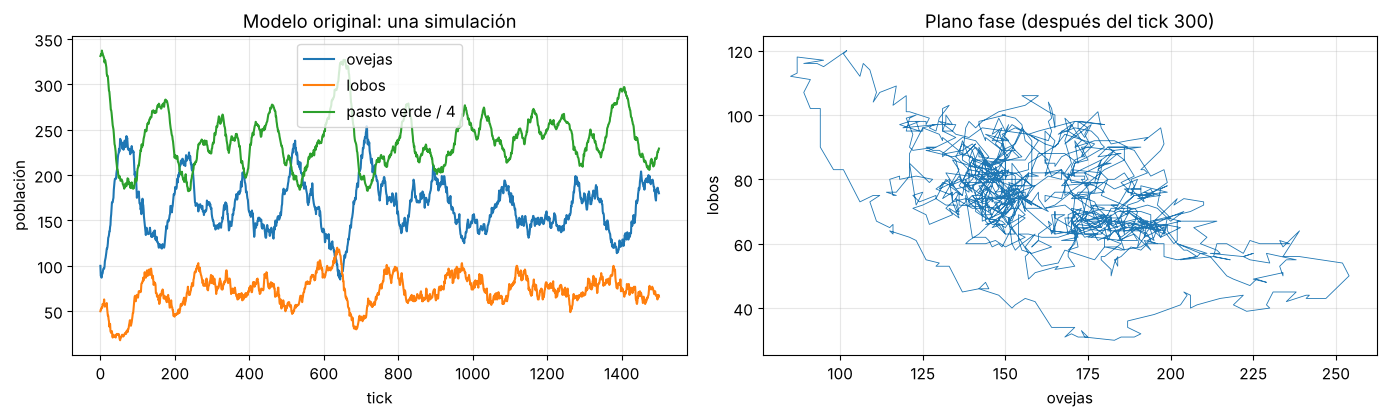

In [3]:
# ============================================================
# Herramientas generales del análisis
# ============================================================
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import solve_ivp

plt.rcParams.update({"figure.dpi": 100, "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(1998)    # semilla fija: resultados reproducibles


def correr_pradera(T, semilla, **kw):
    """
    Corre el modelo presa-depredador T ticks y regresa un arreglo (T + 1, 3)
    con los conteos de ovejas, lobos y parcelas de pasto verde en cada tick.
    Si se extinguen ovejas y lobos, el resto de la serie se llena con ceros.
    """
    p = Pradera(rng=np.random.default_rng(semilla), **kw)
    serie = np.zeros((T + 1, 3))
    serie[0] = p.conteos()
    for t in range(1, T + 1):
        p.paso()
        serie[t] = p.conteos()
        if serie[t, 0] == 0 and serie[t, 1] == 0:
            serie[t:, 2] = p.lado**2          # sin ovejas, todo el pasto acaba verde
            break
    return serie


# Una corrida del modelo original para verlo.
S = correr_pradera(1500, semilla=1)
fig, axs = plt.subplots(1, 2, figsize=(14, 4.3))
axs[0].plot(S[:, 0], label="ovejas")
axs[0].plot(S[:, 1], label="lobos")
axs[0].plot(S[:, 2] / 4, label="pasto verde / 4")
axs[0].set_xlabel("tick")
axs[0].set_ylabel("población")
axs[0].set_title("Modelo original: una simulación")
axs[0].legend()
axs[1].plot(S[300:, 0], S[300:, 1], lw=0.6)
axs[1].set_xlabel("ovejas")
axs[1].set_ylabel("lobos")
axs[1].set_title("Plano fase (después del tick 300)")
plt.tight_layout()
plt.show()

## 2. El modelo de parvada (boids)

En el modelo **Flocking**, cada individuo mira a sus compañeros dentro de un radio `vision` y:

* si su vecino más cercano está a menos de `minimum-separation`: **separación** (gira para alejarse de la dirección de ese vecino, a lo más `max-separate-turn` grados por tick);
* si no: **alineación** (gira hacia el rumbo promedio de sus compañeros, a lo más `max-align-turn`) y **cohesión** (gira hacia la posición promedio de sus compañeros, a lo más `max-cohere-turn`).

Después todos avanzan un paso. Valores por omisión: 300 individuos, visión 5, separación mínima 1, giros máximos de 5° (alinear), 3° (cohesión) y 1.5° (separar).

Para medir cuán "parvada" es el grupo usamos la **polarización**

$$
\varphi = \left\lvert \frac{1}{N}\sum_{k=1}^{N} \big(\sin h_k, \cos h_k\big) \right\rvert ,
$$

donde $h_k$ es el rumbo del individuo $k$. Vale 0 si las direcciones son aleatorias y 1 si todos van exactamente en la misma dirección.

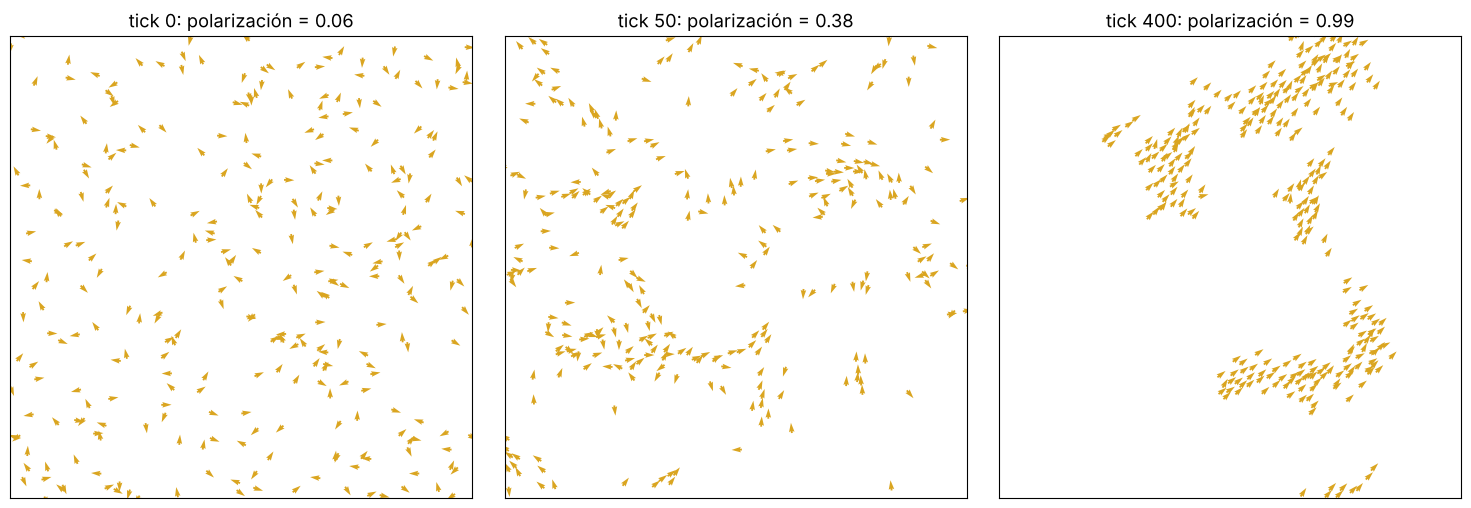

In [4]:
def dibujar_parvada(ax, p, titulo):
    """Dibuja cada individuo como una flecha corta en la dirección de su rumbo."""
    h = np.deg2rad(p.rumbo)
    ax.quiver(p.x, p.y, np.sin(h), np.cos(h), angles="xy", scale=45, width=0.004, color="goldenrod")
    if p.obstaculo > 0:
        ax.add_patch(plt.Circle((0, 0), p.obstaculo, color="gray"))
    lim = p.max_p + 0.5
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(titulo)


p = Parvada(rng=rng)
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, t_obj in zip(axs, [0, 50, 400]):
    while p.ticks < t_obj:
        p.paso()
    dibujar_parvada(ax, p, f"tick {p.ticks}: polarización = {p.polarizacion():.2f}")
plt.tight_layout()
plt.show()

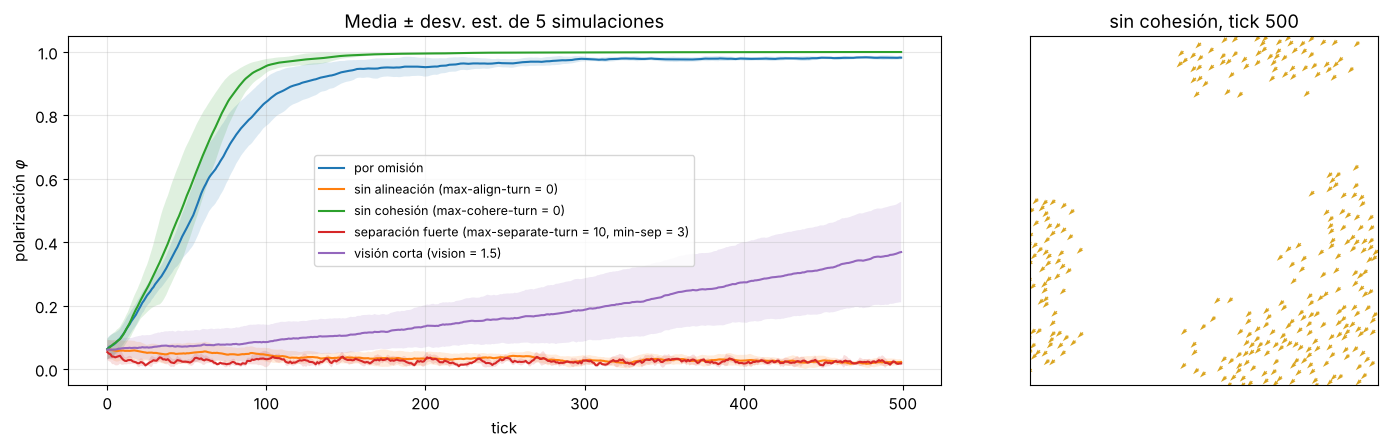

In [5]:
# Experimentamos con los parámetros: quitamos una regla a la vez y medimos la polarización.
variantes = {
    "por omisión": {},
    "sin alineación (max-align-turn = 0)": dict(max_align_turn=0),
    "sin cohesión (max-cohere-turn = 0)": dict(max_cohere_turn=0),
    "separación fuerte (max-separate-turn = 10, min-sep = 3)": dict(max_separate_turn=10, minimum_separation=3),
    "visión corta (vision = 1.5)": dict(vision=1.5),
}
fig, axs = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
finales = {}
for nombre, kw in variantes.items():
    pol = []
    for rep in range(5):
        p = Parvada(rng=np.random.default_rng(100 + rep), **kw)
        serie = []
        for t in range(500):
            p.paso()
            serie.append(p.polarizacion())
        pol.append(serie)
        if rep == 0:
            finales[nombre] = p
    pol = np.array(pol)
    axs[0].plot(pol.mean(0), label=nombre)
    axs[0].fill_between(np.arange(500), pol.mean(0) - pol.std(0), pol.mean(0) + pol.std(0), alpha=0.15)
axs[0].set_xlabel("tick")
axs[0].set_ylabel(r"polarización $\varphi$")
axs[0].set_title("Media ± desv. est. de 5 simulaciones")
axs[0].legend(fontsize=9)
dibujar_parvada(axs[1], finales["sin cohesión (max-cohere-turn = 0)"], "sin cohesión, tick 500")
plt.tight_layout()
plt.show()

**Lectura.** Con los valores por omisión, el grupo pasa en unas decenas de ticks de un desorden total ($\varphi \approx 0$) a moverse casi en la misma dirección ($\varphi \approx 1$), sin líder y sin que nadie conozca el estado global. **La alineación es la regla que produce el orden**: sin ella la polarización se queda cerca de 0. Sin cohesión el grupo se alinea igual, pero no se forman grupos compactos: los individuos se reparten por todo el mundo moviéndose en paralelo. Con una separación fuerte (giros de hasta 10° y distancia mínima de 3) el orden **desaparece**: casi siempre hay un vecino demasiado cerca, así que los individuos pasan el tiempo separándose y nunca llegan a alinearse. Con una visión corta la información viaja más lento y el orden tarda mucho más en aparecer.

### Una transición de fase: del desorden al orden

¿Cuánta alineación hace falta? Variamos `max-align-turn` y medimos la polarización después de 500 ticks.

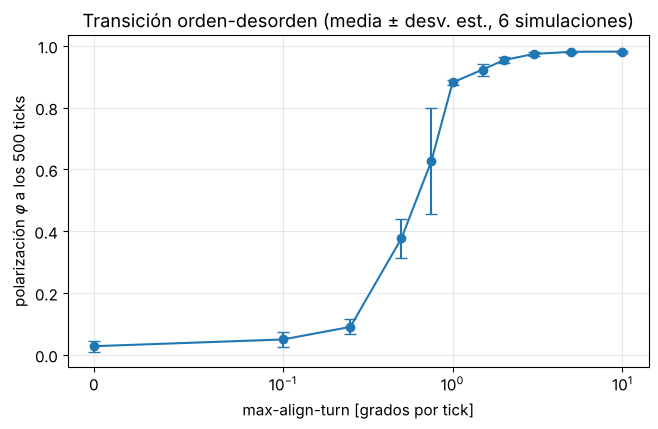

In [6]:
alineaciones = [0, 0.1, 0.25, 0.5, 0.75, 1, 1.5, 2, 3, 5, 10]
pol_media, pol_desv = [], []
for al in alineaciones:
    finales_al = []
    for rep in range(6):
        p = Parvada(max_align_turn=al, rng=np.random.default_rng(200 + rep))
        for t in range(500):
            p.paso()
        finales_al.append(p.polarizacion())
    pol_media.append(np.mean(finales_al))
    pol_desv.append(np.std(finales_al))

plt.figure(figsize=(7.5, 4.3))
plt.errorbar(alineaciones, pol_media, yerr=pol_desv, fmt="o-", capsize=4)
plt.xscale("symlog", linthresh=0.1)
plt.xlabel("max-align-turn [grados por tick]")
plt.ylabel(r"polarización $\varphi$ a los 500 ticks")
plt.title("Transición orden-desorden (media ± desv. est., 6 simulaciones)")
plt.show()

Hay un cambio abrupto: por debajo de unos 0.5° por tick el grupo permanece desordenado, y por encima de 1° por tick se ordena casi por completo. Es el análogo de una **transición de fase** (como la magnetización de un material al bajar la temperatura), y es el fenómeno que estudia el modelo de Vicsek: reglas locales simples producen orden global cuando la interacción supera al ruido.

**¿Cómo resultan reglas tan simples en un comportamiento tan complejo?** Porque cada individuo responde a sus vecinos, y sus vecinos a los suyos: la información sobre la dirección se propaga por toda la parvada a través de interacciones locales repetidas. Ninguna regla dice "formen una parvada"; la parvada es una propiedad **emergente** de la interacción.

### Obstáculos

Agregamos un obstáculo circular en el centro: cuando un individuo está cerca y se dirige hacia él, gira (a lo más 20° por tick) para alejarse, y nunca puede entrar.

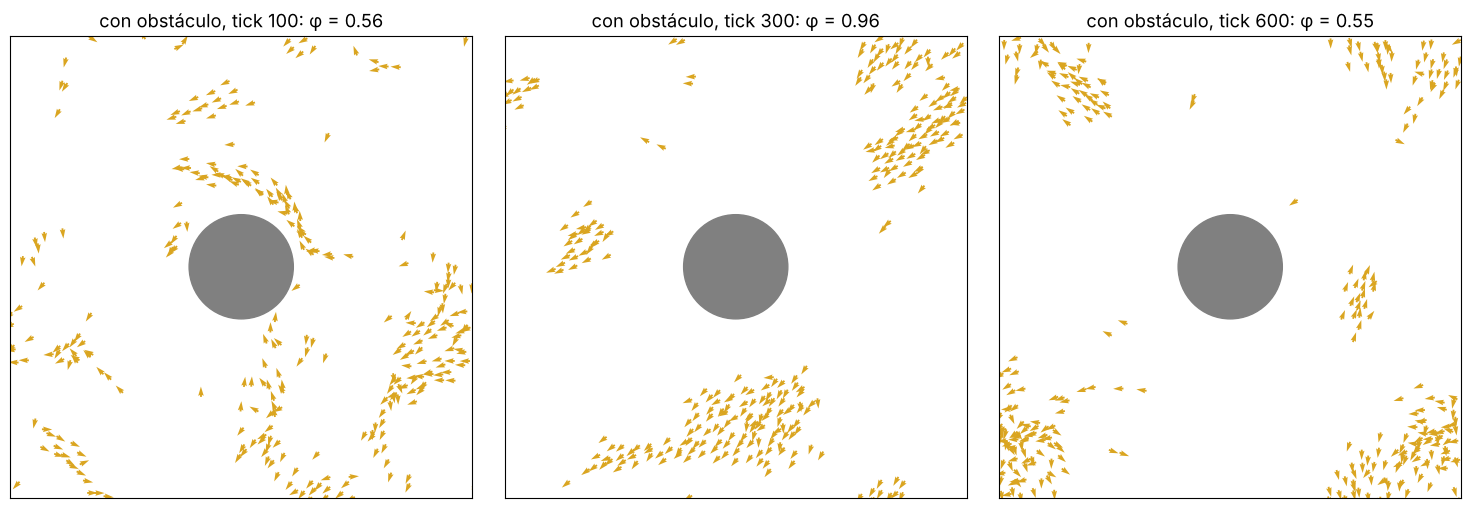

In [7]:
p = Parvada(obstaculo=8, rng=np.random.default_rng(3))
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, t_obj in zip(axs, [100, 300, 600]):
    while p.ticks < t_obj:
        p.paso()
    dibujar_parvada(ax, p, f"con obstáculo, tick {p.ticks}: φ = {p.polarizacion():.2f}")
plt.tight_layout()
plt.show()

Los individuos rodean el obstáculo sin entrar, pero el obstáculo **parte** las parvadas: los que lo esquivan por un lado y por el otro salen con direcciones distintas, y en un mundo periódico los grupos vuelven a encontrarlo una y otra vez. Por eso la polarización global ya no se queda cerca de 1, sino que fluctúa (sube cuando los grupos se reúnen y vuelve a bajar en el siguiente encuentro con el obstáculo). Un solo obstáculo basta para mantener al sistema en un estado de grupos que se separan y se juntan.

## 3. Ovejas en rebaño

En `Pradera(rebano=True)`, las ovejas aplican en cada tick las reglas de parvada con parámetros adaptados al mundo de 51 × 51 (visión 3, separación mínima 1, giros máximos 5°, 3° y 1.5°) y después un pequeño **ruido** (`rt random 15  lt random 15`), porque las ovejas no se mueven como pájaros en formación perfecta: pastan y se desvían. Los lobos se siguen moviendo al azar. En NetLogo es el procedimiento `mover-oveja` con el interruptor `rebano?`.

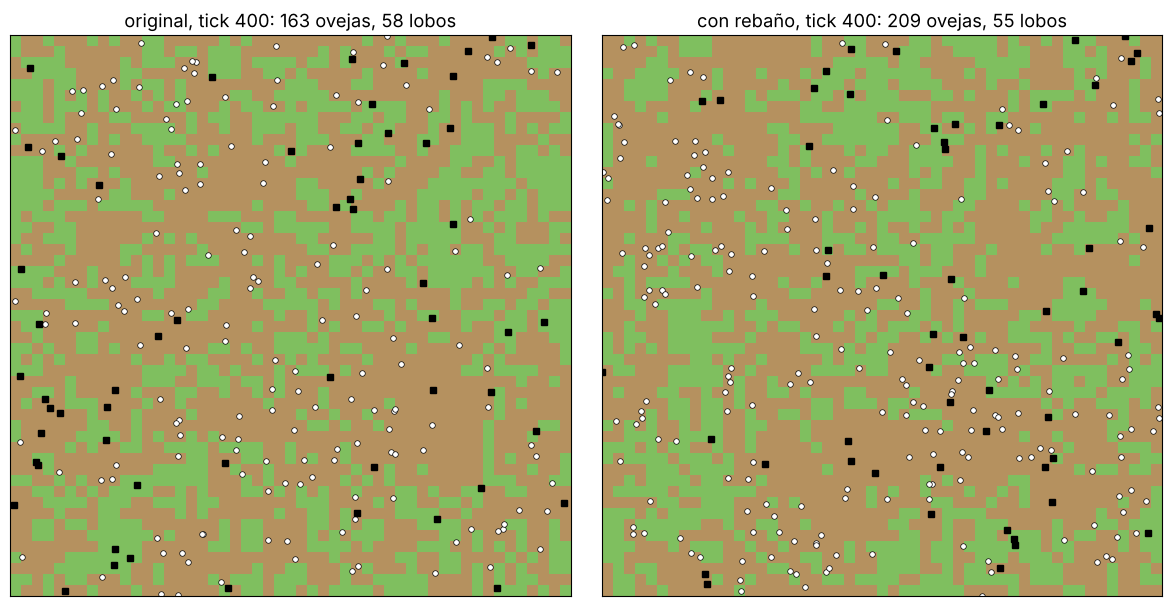

In [8]:
def dibujar_pradera(ax, p, titulo):
    """Pasto (verde/café), ovejas (blanco con borde) y lobos (negro)."""
    m = p.max_p
    ax.imshow(p.verde.T, origin="lower", extent=(-m - 0.5, m + 0.5, -m - 0.5, m + 0.5),
              cmap=plt.matplotlib.colors.ListedColormap(["#b5915f", "#7fbf5f"]), vmin=0, vmax=1)
    ax.plot(p.ox, p.oy, "o", ms=4, mfc="white", mec="k", mew=0.5)
    ax.plot(p.lx, p.ly, "s", ms=4, color="k")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.set_title(titulo)


fig, axs = plt.subplots(1, 2, figsize=(12, 6))
for ax, reb in zip(axs, [False, True]):
    p = Pradera(rebano=reb, rng=np.random.default_rng(11))
    for t in range(400):
        p.paso()
    ov, lo, pa = p.conteos()
    dibujar_pradera(ax, p, f"{'con rebaño' if reb else 'original'}, tick 400: {ov} ovejas, {lo} lobos")
plt.tight_layout()
plt.show()

A simple vista la diferencia es sutil: con 150–200 ovejas en 51 × 51 parcelas, visión 3 y ruido, se forman grupos pequeños y laxos, no un gran rebaño. Las crías, además, aparecen en direcciones al azar. Para no depender de la vista, medimos la **agregación**: el número promedio de otras ovejas a menos de 2 parcelas de cada oveja, dividido entre el que se esperaría si las ovejas estuvieran repartidas al azar (índice 1 = sin agregación).

In [9]:
def indice_agregacion(p, radio=2.0):
    """Vecinas promedio a menos de `radio`, relativo a ovejas repartidas uniformemente al azar."""
    n = len(p.ox)
    if n < 2:
        return np.nan
    arbol = cKDTree(np.column_stack([p.ox % p.lado, p.oy % p.lado]), boxsize=p.lado)
    vecinas = 2 * len(arbol.query_pairs(radio)) / n
    esperado = (n - 1) * np.pi * radio**2 / p.lado**2
    return vecinas / esperado


for etiqueta, kw in [("original", dict()), ("rebaño, visión 3", dict(rebano=True)),
                     ("rebaño, visión 5", dict(rebano=True, vision=5)),
                     ("rebaño, visión 5, sin ruido", dict(rebano=True, vision=5, ruido=1))]:
    valores = []
    for rep in range(5):
        p = Pradera(rng=np.random.default_rng(300 + rep), **kw)
        for t in range(1000):
            p.paso()
            if t >= 300 and t % 20 == 0:
                valores.append(indice_agregacion(p))
    print(f"{etiqueta:30s}: índice de agregación = {np.nanmean(valores):.2f}")

original                      : índice de agregación = 1.23


rebaño, visión 3              : índice de agregación = 1.68


rebaño, visión 5              : índice de agregación = 1.73


rebaño, visión 5, sin ruido   : índice de agregación = 1.84


Incluso en el modelo original el índice es algo mayor que 1, porque las crías nacen a un paso de su madre. Con rebaño sube a cerca de 1.7: las ovejas tienen casi el doble de vecinas cercanas que si estuvieran al azar, y la agregación crece con la visión y al quitar el ruido. Los lobos, que siguen moviéndose al azar, encuentran ovejas con menos frecuencia porque los grupos dejan huecos, aunque cuando las encuentran hay varias a la vez.

## 4. Reproducción gradual

En `Pradera(gradual=True)`, cada oveja tiene una **edad** que aumenta un tick por tick. Una oveja solo puede reproducirse (con la misma probabilidad de 4 %) si

* su edad es al menos `edad_madurez` (por omisión 20 ticks), y
* su energía es al menos `energia_minima` (por omisión 4, es decir, "estar sana").

Las crías nacen con edad 0. Así la población tiene una **estructura de edades**: corderos que todavía no se reproducen y adultas que sí, como los huevos y las adultas del modelo de cucarachas. El efecto principal es un **retraso** entre que la población de ovejas crece y que esas ovejas nuevas aportan crías.

## 5. Muchas simulaciones

Comparamos cuatro versiones: la original, con rebaño, con reproducción gradual y con ambas. Para cada una corremos 30 simulaciones de 2000 ticks y medimos:

* la probabilidad de que se extingan los lobos o las ovejas;
* en las simulaciones donde coexisten, las poblaciones promedio, la **amplitud** de las oscilaciones de ovejas (desviación estándar en el tiempo) y su **periodo** (primer máximo de la autocorrelación), descartando los primeros 300 ticks como transitorio.

*(Esta celda tarda unos minutos.)*

In [10]:
VERSIONES = {"original": dict(), "rebaño": dict(rebano=True),
             "gradual": dict(gradual=True), "rebaño + gradual": dict(rebano=True, gradual=True)}
N_REP, T = 30, 2000
TRANS = 300                     # transitorio que descartamos


def periodo_dominante(x, max_lag=800):
    """Periodo por autocorrelación: el primer máximo después del primer cruce por cero."""
    x = x - x.mean()
    if np.allclose(x, 0):
        return np.nan
    ac = np.correlate(x, x, mode="full")[len(x) - 1:]
    ac /= ac[0]
    cruce = np.argmax(ac < 0)
    if cruce == 0:
        return np.nan
    k = cruce + np.argmax(ac[cruce:max_lag])
    return k if ac[k] > 0.1 else np.nan


series = {v: np.array([correr_pradera(T, semilla=7000 + r, **kw) for r in range(N_REP)])
          for v, kw in VERSIONES.items()}

print(f"{'versión':18s} {'P(ext. lobos)':>14s} {'P(ext. ovejas)':>15s} {'ovejas':>12s} {'lobos':>12s}"
      f" {'amplitud ov.':>14s} {'periodo':>12s}")
metricas = {}
for v, S in series.items():
    ext_l = S[:, -1, 1] == 0
    ext_o = S[:, -1, 0] == 0
    coex = ~ext_l & ~ext_o
    ov = S[coex, TRANS:, 0]
    lo = S[coex, TRANS:, 1]
    amp = ov.std(axis=1)
    per = np.array([periodo_dominante(s) for s in ov])
    metricas[v] = dict(ext_l=ext_l, ext_o=ext_o, amp=amp, per=per)
    print(f"{v:18s} {ext_l.mean():14.2f} {ext_o.mean():15.2f} {ov.mean():7.0f} ± {ov.mean(1).std():3.0f}"
          f" {lo.mean():7.0f} ± {lo.mean(1).std():3.0f} {amp.mean():8.1f} ± {amp.std():4.1f}"
          f" {np.nanmean(per):7.0f} ± {np.nanstd(per):3.0f}")

versión             P(ext. lobos)  P(ext. ovejas)       ovejas        lobos   amplitud ov.      periodo
original                     0.00            0.00     160 ±   2      76 ±   1     25.3 ±  3.5     374 ± 223
rebaño                       0.00            0.00     160 ±   2      69 ±   1     24.8 ±  3.1     344 ± 201
gradual                      0.00            0.00     164 ±   3      57 ±   1     32.2 ±  5.9     236 ±  92
rebaño + gradual             0.03            0.00     164 ±   4      49 ±   2     30.3 ±  6.8     327 ± 187


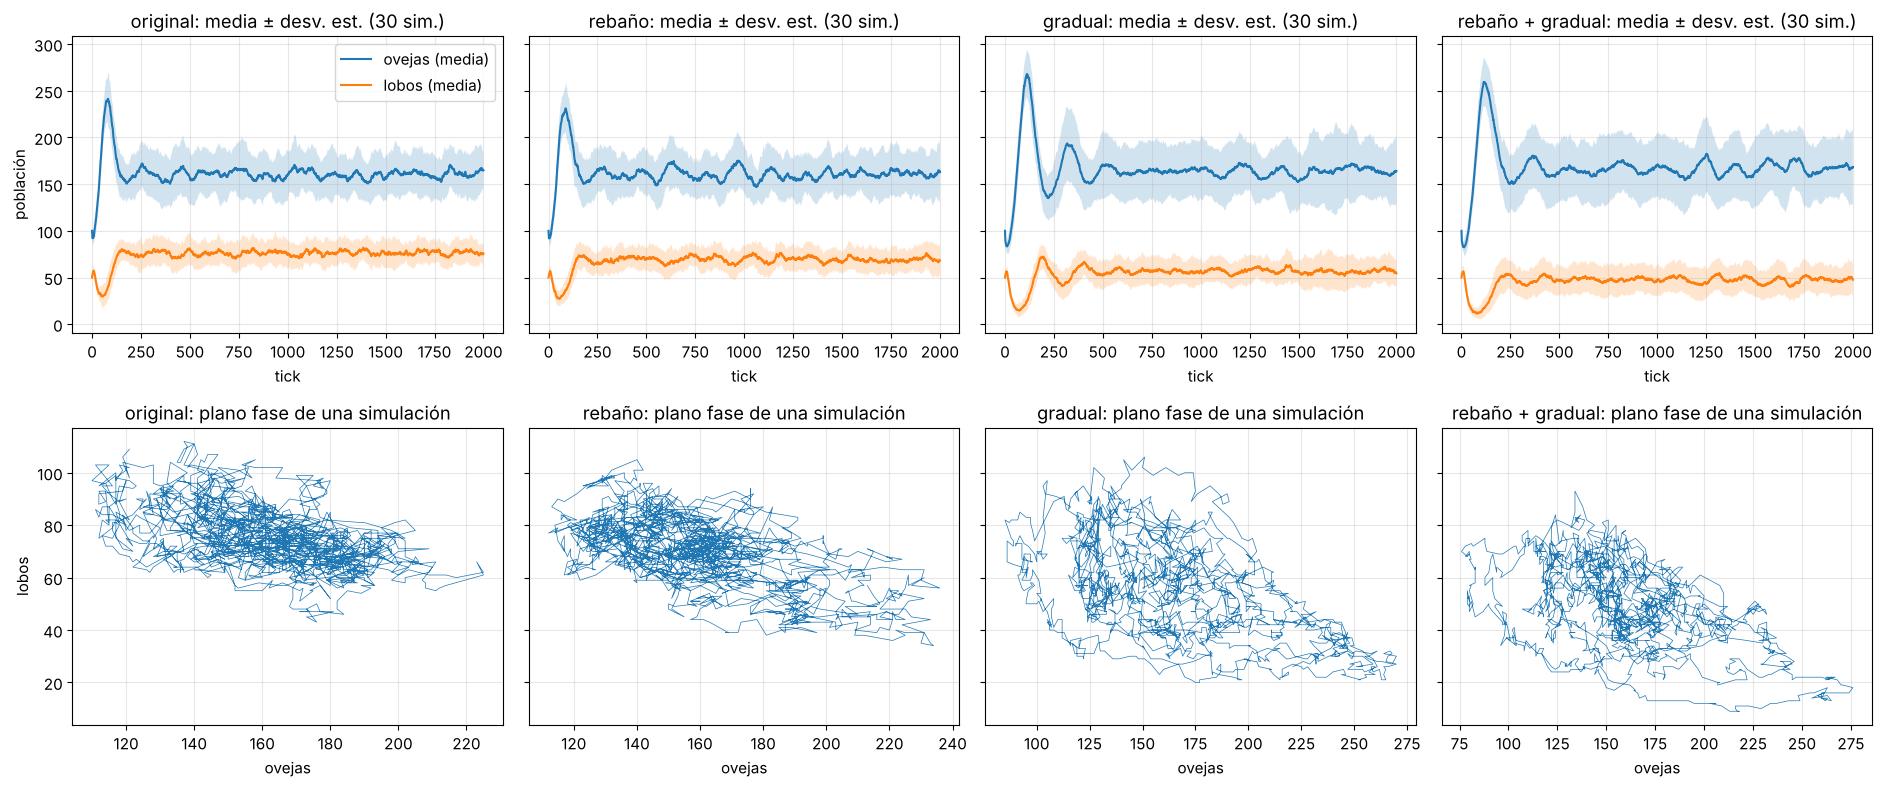

In [11]:
fig, axs = plt.subplots(2, 4, figsize=(19, 8), sharey="row")
for k, (v, S) in enumerate(series.items()):
    tt = np.arange(T + 1)
    for col, nombre in [(0, "ovejas"), (1, "lobos")]:
        m, s = S[:, :, col].mean(0), S[:, :, col].std(0)
        axs[0, k].plot(tt, m, label=f"{nombre} (media)")
        axs[0, k].fill_between(tt, m - s, m + s, alpha=0.2)
    axs[0, k].set_title(f"{v}: media ± desv. est. ({N_REP} sim.)")
    axs[0, k].set_xlabel("tick")
    # Una simulación individual en el plano fase.
    axs[1, k].plot(S[0, TRANS:, 0], S[0, TRANS:, 1], lw=0.5)
    axs[1, k].set_xlabel("ovejas")
    axs[1, k].set_title(f"{v}: plano fase de una simulación")
axs[0, 0].set_ylabel("población")
axs[0, 0].legend()
axs[1, 0].set_ylabel("lobos")
plt.tight_layout()
plt.show()

In [12]:
# ¿Son significativas las diferencias de amplitud respecto al original? (Mann-Whitney)
base = metricas["original"]["amp"]
for v in list(VERSIONES)[1:]:
    p_amp = stats.mannwhitneyu(metricas[v]["amp"], base).pvalue
    print(f"{v:18s}: amplitud {metricas[v]['amp'].mean():5.1f} contra {base.mean():5.1f} (original), p = {p_amp:.4f}")

rebaño            : amplitud  24.8 contra  25.3 (original), p = 0.5895
gradual           : amplitud  32.2 contra  25.3 (original), p = 0.0000
rebaño + gradual  : amplitud  30.3 contra  25.3 (original), p = 0.0037


### ¿Hay una transición? Variando la edad de madurez

La reproducción gradual introduce un retraso. Para ver su efecto con claridad variamos `edad_madurez` desde 0 (equivalente al original, salvo el umbral de energía) hasta 140 ticks, con 20 simulaciones de 1500 ticks por valor, y medimos la probabilidad de que se extingan los lobos y la amplitud de las oscilaciones de las ovejas.

edad de madurez =   0: P(extinción de lobos) = 0.00, amplitud de ovejas = 23.4


edad de madurez =  10: P(extinción de lobos) = 0.00, amplitud de ovejas = 27.1


edad de madurez =  20: P(extinción de lobos) = 0.00, amplitud de ovejas = 30.8


edad de madurez =  30: P(extinción de lobos) = 0.00, amplitud de ovejas = 37.3


edad de madurez =  40: P(extinción de lobos) = 0.10, amplitud de ovejas = 40.2


edad de madurez =  60: P(extinción de lobos) = 0.10, amplitud de ovejas = 44.8


edad de madurez =  80: P(extinción de lobos) = 0.30, amplitud de ovejas = 46.6


edad de madurez = 100: P(extinción de lobos) = 0.45, amplitud de ovejas = 46.3


edad de madurez = 140: P(extinción de lobos) = 0.85, amplitud de ovejas = 44.3


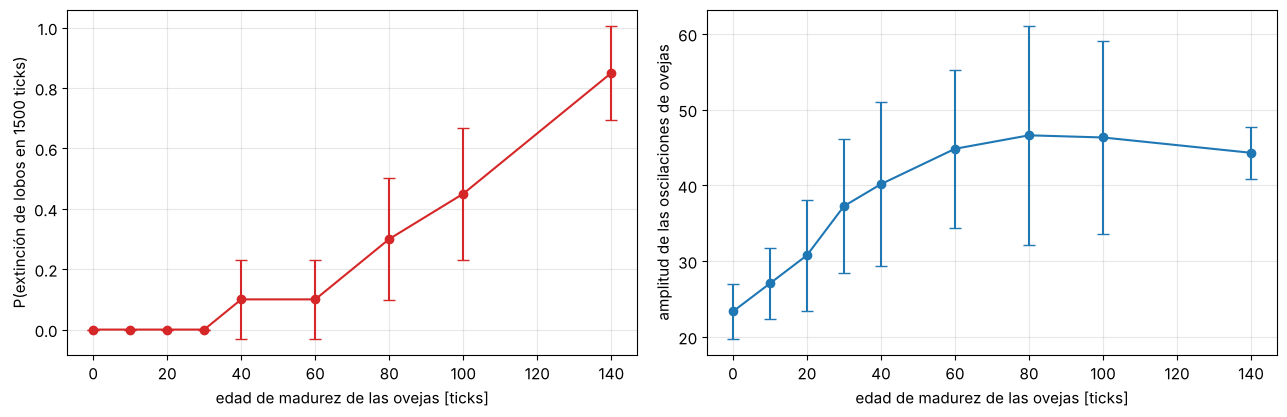

In [13]:
edades = [0, 10, 20, 30, 40, 60, 80, 100, 140]
p_ext, ic_ext, amp_m, amp_s = [], [], [], []
for A in edades:
    S = np.array([correr_pradera(1500, semilla=9000 + r, gradual=True, edad_madurez=A) for r in range(20)])
    ext = S[:, -1, 1] == 0
    p_ext.append(ext.mean())
    ic_ext.append(1.96 * np.sqrt(ext.mean() * (1 - ext.mean()) / len(ext)))   # error binomial aproximado
    vivas = ~ext & (S[:, -1, 0] > 0)
    a = S[vivas, TRANS:, 0].std(axis=1)
    amp_m.append(a.mean() if len(a) else np.nan)
    amp_s.append(a.std() if len(a) else np.nan)
    print(f"edad de madurez = {A:3d}: P(extinción de lobos) = {ext.mean():.2f}, "
          f"amplitud de ovejas = {amp_m[-1]:.1f}")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.3))
axs[0].errorbar(edades, p_ext, yerr=ic_ext, fmt="o-", capsize=4, color="C3")
axs[0].set_xlabel("edad de madurez de las ovejas [ticks]")
axs[0].set_ylabel("P(extinción de lobos en 1500 ticks)")
axs[1].errorbar(edades, amp_m, yerr=amp_s, fmt="o-", capsize=4)
axs[1].set_xlabel("edad de madurez de las ovejas [ticks]")
axs[1].set_ylabel("amplitud de las oscilaciones de ovejas")
plt.tight_layout()
plt.show()

### ¿Y el tamaño de los rebaños? Variando la visión

Con rebaño, la `vision` controla de qué tamaño son los grupos: con más visión, cada oveja se coordina con más vecinas y los rebaños son más grandes y compactos.

visión = 1: P(ext. lobos) = 0.00, ovejas = 159, lobos = 77, amplitud de ovejas = 26.0


visión = 2: P(ext. lobos) = 0.00, ovejas = 160, lobos = 71, amplitud de ovejas = 25.9


visión = 3: P(ext. lobos) = 0.00, ovejas = 159, lobos = 70, amplitud de ovejas = 24.3


visión = 5: P(ext. lobos) = 0.00, ovejas = 161, lobos = 64, amplitud de ovejas = 25.3


visión = 8: P(ext. lobos) = 0.00, ovejas = 160, lobos = 60, amplitud de ovejas = 27.1


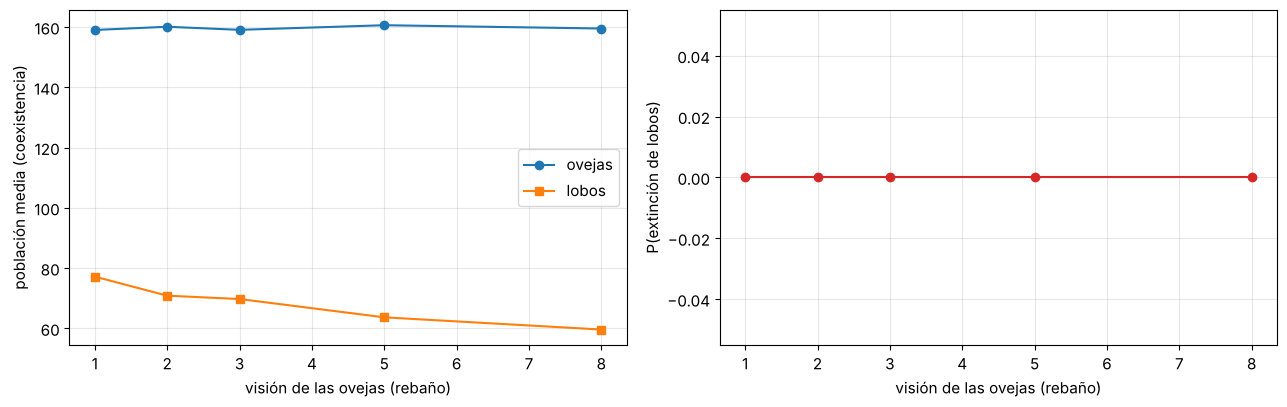

In [14]:
visiones = [1, 2, 3, 5, 8]
res_vision = []
for vis in visiones:
    S = np.array([correr_pradera(1500, semilla=11000 + r, rebano=True, vision=vis) for r in range(15)])
    ext = S[:, -1, 1] == 0
    coex = ~ext & (S[:, -1, 0] > 0)
    res_vision.append((ext.mean(), S[coex, TRANS:, 0].mean(), S[coex, TRANS:, 1].mean(),
                       S[coex, TRANS:, 0].std(axis=1).mean()))
    print(f"visión = {vis}: P(ext. lobos) = {ext.mean():.2f}, ovejas = {res_vision[-1][1]:.0f}, "
          f"lobos = {res_vision[-1][2]:.0f}, amplitud de ovejas = {res_vision[-1][3]:.1f}")

R = np.array(res_vision)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
axs[0].plot(visiones, R[:, 1], "o-", label="ovejas")
axs[0].plot(visiones, R[:, 2], "s-", label="lobos")
axs[0].set_xlabel("visión de las ovejas (rebaño)")
axs[0].set_ylabel("población media (coexistencia)")
axs[0].legend()
axs[1].plot(visiones, R[:, 0], "o-", color="C3")
axs[1].set_xlabel("visión de las ovejas (rebaño)")
axs[1].set_ylabel("P(extinción de lobos)")
plt.tight_layout()
plt.show()

## 6. Comparación con el modelo continuo

El modelo continuo clásico es Lotka–Volterra:

$$
\dot S = \alpha S - \beta S W, \qquad \dot W = \delta S W - \gamma W .
$$

Sus órbitas son **ciclos neutros**: cada condición inicial da una órbita cerrada distinta, sin ninguna que atraiga a las demás. Basta una perturbación para saltar a otra órbita, así que con ruido la amplitud deriva como una caminata aleatoria hasta que alguna población toca cero. Si la presa tiene un recurso limitado (crecimiento logístico, como el pasto aquí), el equilibrio se vuelve un **foco estable**: las oscilaciones se amortiguan.

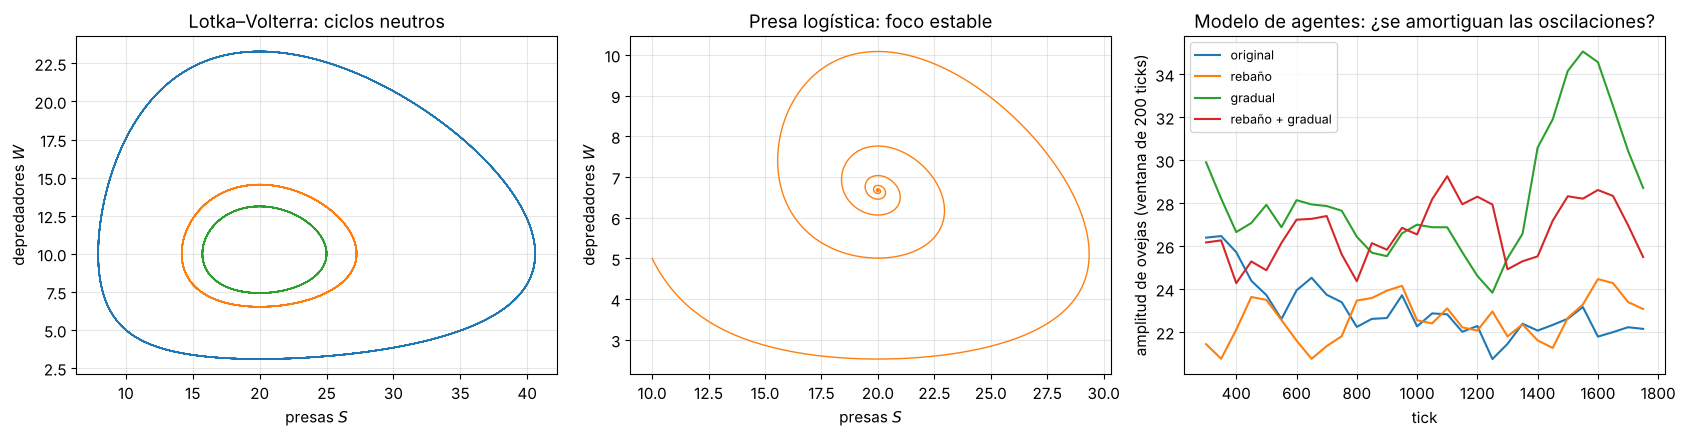

In [15]:
def lotka_volterra(t, z, a=1.0, b=0.1, d=0.075, g=1.5, K=None):
    """Lotka-Volterra; si K no es None, la presa crece logísticamente con capacidad K."""
    S, W = z
    crecimiento = a * S * (1 - S / K) if K else a * S
    return [crecimiento - b * S * W, d * S * W - g * W]


fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
for z0 in [(10, 5), (15, 8), (25, 10)]:
    sol = solve_ivp(lotka_volterra, (0, 40), z0, max_step=0.01)
    axs[0].plot(sol.y[0], sol.y[1], lw=1)
axs[0].set_title("Lotka–Volterra: ciclos neutros")
sol = solve_ivp(lotka_volterra, (0, 80), (10, 5), max_step=0.01, args=(1.0, 0.1, 0.075, 1.5, 60))
axs[1].plot(sol.y[0], sol.y[1], lw=1, color="C1")
axs[1].set_title("Presa logística: foco estable")
for ax in axs[:2]:
    ax.set_xlabel("presas $S$")
    ax.set_ylabel("depredadores $W$")
# Comparación: amplitud relativa a lo largo del tiempo en el modelo de agentes
for v in VERSIONES:
    S = series[v]
    coex = (S[:, -1, 0] > 0) & (S[:, -1, 1] > 0)
    ov = S[coex][:, :, 0]
    # desviación estándar móvil (ventana de 200 ticks) promediada entre simulaciones
    ventana = 200
    cv = [ov[:, t:t + ventana].std(axis=1).mean() for t in range(TRANS, T - ventana, 50)]
    axs[2].plot(range(TRANS, T - ventana, 50), cv, label=v)
axs[2].set_xlabel("tick")
axs[2].set_ylabel("amplitud de ovejas (ventana de 200 ticks)")
axs[2].set_title("Modelo de agentes: ¿se amortiguan las oscilaciones?")
axs[2].legend(fontsize=9)
plt.tight_layout()
plt.show()

## 7. Verificación con NetLogo

¿Coincide la reimplementación con el modelo de NetLogo modificado? Corrimos `Wolf-Sheep-Rebano.nlogo` en NetLogo 6.4.0 (sin interfaz gráfica, con `netlogo-headless.sh`) con los dos experimentos de BehaviorSpace incluidos en el archivo:

* `cuatro-versiones`: 30 simulaciones de 2000 ticks de cada versión. Guardamos los conteos cada 10 ticks en [`_data/netlogo_cuatro-versiones_cada10.csv`](https://github.com/uncrayon/biologia-matematica/blob/main/_data/netlogo_cuatro-versiones_cada10.csv).
* `barrido-edad-madurez`: 20 simulaciones de 1500 ticks para cada edad de madurez, en [`_data/netlogo_barrido-edad-madurez.csv`](https://github.com/uncrayon/biologia-matematica/blob/main/_data/netlogo_barrido-edad-madurez.csv).

versión                     P(ext. lobos)         ovejas          lobos      amplitud ovejas
                         NetLogo | Python NetLogo|Python NetLogo|Python     NetLogo | Python
original                0.00 | 0.00        161 | 160      76 |  76        25.7 | 25.3
gradual                 0.00 | 0.00        163 | 164      56 |  57        33.5 | 32.2
rebaño                  0.00 | 0.00        162 | 160      69 |  69        25.4 | 24.8
rebaño + gradual        0.00 | 0.03        163 | 164      50 |  49        29.0 | 30.3


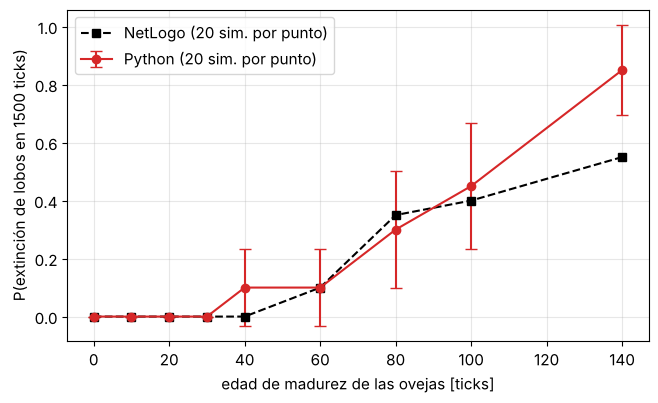

NetLogo, P(extinción de lobos): {0: 0.0, 10: 0.0, 20: 0.0, 30: 0.0, 40: 0.0, 60: 0.1, 80: 0.35, 100: 0.4, 140: 0.55}


In [16]:
import pathlib
import pandas as pd


def leer_datos(nombre):
    """Lee un CSV de _data/ (copia local o, en Colab, desde GitHub)."""
    ruta = pathlib.Path("../_data") / nombre
    url = "https://raw.githubusercontent.com/uncrayon/biologia-matematica/main/_data/" + nombre
    return pd.read_csv(ruta if ruta.exists() else url)


cuatro = leer_datos("netlogo_cuatro-versiones_cada10.csv")
nombre_version = {(False, False): "original", (True, False): "rebaño",
                  (False, True): "gradual", (True, True): "rebaño + gradual"}
print(f"{'versión':18s} {'P(ext. lobos)':>22s} {'ovejas':>14s} {'lobos':>14s} {'amplitud ovejas':>20s}")
print(f"{'':18s} {'NetLogo | Python':>22s} {'NetLogo|Python':>14s} {'NetLogo|Python':>14s} {'NetLogo | Python':>20s}")
for (reb, grad), g in cuatro.groupby(["rebano?", "reproduccion-gradual?"]):
    v = nombre_version[(bool(reb), bool(grad))]
    final = g.sort_values("[step]").groupby("[run number]").last()
    ext = (final["count wolves"] == 0).mean()
    vivas = final.index[(final["count wolves"] > 0) & (final["count sheep"] > 0)]
    tramo = g[(g["[step]"] >= TRANS) & g["[run number]"].isin(vivas)]
    amp = tramo.groupby("[run number]")["count sheep"].std().mean()
    S = series[v]
    coex = (S[:, -1, 0] > 0) & (S[:, -1, 1] > 0)
    print(f"{v:18s} {ext:9.2f} | {metricas[v]['ext_l'].mean():.2f}      "
          f"{tramo['count sheep'].mean():5.0f} | {S[coex, TRANS:, 0].mean():3.0f}   "
          f"{tramo['count wolves'].mean():5.0f} | {S[coex, TRANS:, 1].mean():3.0f}   "
          f"{amp:9.1f} | {metricas[v]['amp'].mean():.1f}")

barrido = leer_datos("netlogo_barrido-edad-madurez.csv")
p_nl = barrido.groupby("edad-madurez")["count wolves"].apply(lambda w: (w == 0).mean())
plt.figure(figsize=(7.5, 4.3))
plt.errorbar(edades, p_ext, yerr=ic_ext, fmt="o-", capsize=4, color="C3", label="Python (20 sim. por punto)")
plt.plot(p_nl.index, p_nl.values, "s--", color="k", label="NetLogo (20 sim. por punto)")
plt.xlabel("edad de madurez de las ovejas [ticks]")
plt.ylabel("P(extinción de lobos en 1500 ticks)")
plt.legend()
plt.show()
print("NetLogo, P(extinción de lobos):", p_nl.round(2).to_dict())

**Lectura.** Las dos implementaciones coinciden muy bien: poblaciones promedio, amplitud de las oscilaciones y el efecto de cada modificación (el rebaño baja el número de lobos de unos 76 a unos 69; la reproducción gradual lo baja a unos 56 y aumenta la amplitud). La transición con la edad de madurez también aparece en NetLogo: la extinción de los lobos empieza alrededor de los 40–60 ticks de madurez y crece después. Los valores puntuales difieren algo (con edad 140, 0.55 en NetLogo y 0.85 en Python), lo esperable con solo 20 simulaciones por punto (el error estándar de cada proporción es de hasta 0.11) y con la pequeña diferencia de que en Python los agentes actúan a la vez y en NetLogo uno tras otro.

## Conclusiones

Los números exactos están en las tablas de arriba; aquí resumimos lo que muestran.

1. **Modelo original.** Con pasto, lobos y ovejas coexisten en todas las simulaciones y oscilan de forma irregular pero **sostenida**: la amplitud no decae con el tiempo. En el continuo, el pasto haría que las oscilaciones se amortiguaran (foco estable); en el modelo de agentes, la **aleatoriedad** de nacimientos, muertes y encuentros las mantiene vivas. Son oscilaciones sostenidas por el ruido (*cuasiciclos*), no un ciclo límite determinista.
2. **Rebaño.** Agrupar a las ovejas cambia la geometría de los encuentros: la depredación ya no es de "acción de masas". En nuestras simulaciones el número de lobos baja un poco (encuentran ovejas con menos frecuencia) y las oscilaciones cambian poco. Es un efecto moderado con estos parámetros. Con rebaños más grandes (más visión) el efecto crece.
3. **Reproducción gradual.** Es el cambio con más consecuencias. El retraso entre nacer y poder reproducirse hace que las ovejas respondan tarde a la abundancia de pasto y a la disminución de lobos. Las oscilaciones se hacen **más grandes**, y en el mínimo de cada ciclo hay menos ovejas para alimentar a los lobos. Al aumentar la edad de madurez, la amplitud crece y la probabilidad de que los lobos se extingan pasa de prácticamente 0 a valores apreciables. Es un **cambio cualitativo** en la dinámica (de coexistencia robusta a extinción frecuente del depredador), el análogo estocástico de una bifurcación inducida por retraso, como las que vimos en el problema 2 con los glóbulos rojos.
4. **¿Más sensible a extinguirse alguna especie?** Sí, los **lobos**. Las ovejas casi nunca se extinguen, porque cuando los lobos desaparecen el pasto las limita. Los lobos, en cambio, dependen de que siempre haya ovejas suficientes, y una oscilación grande de las ovejas los deja sin comida.
5. **Modelo continuo contra modelo de agentes.** Lotka–Volterra predice ciclos neutros y la versión con presa logística, oscilaciones amortiguadas. El modelo de agentes muestra algo intermedio: un equilibrio que en promedio es estable, alrededor del cual el ruido demográfico mantiene oscilaciones. Además, la población es un número entero y puede llegar a cero, algo imposible en las ecuaciones. El retraso de maduración empuja el sistema hacia oscilaciones más grandes, como en los modelos continuos con retraso.

**Referencias:** Wilensky, U. (1997). NetLogo Wolf Sheep Predation model. Wilensky, U. (1998). NetLogo Flocking model. Reynolds, C. (1987). Flocks, herds and schools: A distributed behavioral model. *Computer Graphics* 21(4). Vicsek, T. et al. (1995). *Phys. Rev. Lett.* 75: 1226. Hamilton, W. D. (1971). Geometry for the selfish herd. *J. Theor. Biol.* 31: 295–311. King, A. J. et al. (2012). Selfish-herd behaviour of sheep under threat. *Current Biology* 22: R561–R562.